# interpolation_station_grid 方法说明

将站点观测融合到规则格点。包内四个插件：

| 插件 | 典型用途 |
| --- | --- |
| `InterpSgIdw` | 反距离权重；可选高斯衰减与背景偏差订正 |
| `InterpSgGaussian` | 最近邻 × 高斯半径扩散；可选背景偏差订正 |
| `InterpSgKriging` | 局部普通克里金；可选背景偏差订正 |
| `InterpSgCressman` | Cressman 逐步订正；可选背景作初估场 |

接口统一为 `process(sta, grid, background=None)`。在包根或本 `nbs/` 目录打开即可运行（依赖 `meteva_base`，样例在 `resource/`）。


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import meteva_base as meb
import numpy as np
import pandas as pd
from meteva_base.tool.color_tools import (
    def_cmap_clevs,
    get_cmap_and_clevs_by_element_name,
)

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

PACKAGE_ROOT = Path.cwd().resolve()
if PACKAGE_ROOT.name == "nbs":
    PACKAGE_ROOT = PACKAGE_ROOT.parent
DATA_DIR = PACKAGE_ROOT / "resource"

src_s, root_s = str(PACKAGE_ROOT / "src"), str(PACKAGE_ROOT)
for p in (src_s, root_s):
    if p in sys.path:
        sys.path.remove(p)
sys.path.insert(0, src_s)
sys.path.insert(0, root_s)

from interp_sg_cressman_plugin import InterpSgCressman
from interp_sg_gaussian_plugin import InterpSgGaussian
from interp_sg_idw_plugin import InterpSgIdw
from interp_sg_kriging import InterpSgKriging


d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## 1. 原理

接口统一为 `process(sta, grid, background=None)`：`sta` 为站点表，`grid` 为目标 `meb.grid`（或可抽出网格的格点场），`background` 可选。

| 方法 | 原理 |
| --- | --- |
| **InterpSgIdw** | 近邻反距离加权；`gaussian=True` 时再乘高斯核；有背景则插 `obs−bg` 再叠回 |
| **InterpSgGaussian** | 每格点取最近 1 站，权重 `exp(-(d/halfR)^2)`；有背景同上偏差订正 |
| **InterpSgKriging** | 局部普通克里金；矩阵奇异时退化为 IDW；有背景同上偏差订正 |
| **InterpSgCressman** | 多半径逐步订正；无背景初估为 0，有背景则以对齐后背景为初估场 |

共同约定：按 `member`/`level`/`time`/`dtime` 切片后拼接；站点坐标转球面笛卡尔后用 KDTree 找近邻（距离为米量级）；有 `background` 时用 `InterpGgLinear` 对齐到目标网格。


## 2. 参数

| 参数 | 位置 | 说明 |
| --- | --- | --- |
| `effectR` / `nearNum` / `decrease` / `gaussian` | IDW 构造 | 影响半径（米）、近邻数、衰减指数、是否乘高斯 |
| `halfR` | Gaussian 构造 | 高斯半径（米），须 `> 0` |
| `model` / `sill` / `range_` / `nugget` / `nearNum` | Kriging 构造 | 变异函数与近邻数 |
| `r_list` / `nearNum` | Cressman 构造 | 影响半径列表（米，通常由大到小）、近邻上限 |
| `outer_value` | 各插件构造 | 背景对齐越界填充，传给 `InterpGgLinear` |
| `sta` / `grid` / `background` | `process` | 站点表、目标网格、可选背景场 |

更细说明见 `docs/interpolation_station_grid.md`。


## 3. 读入样例数据

- 站点：`resource/20260602000000.csv`（`obs_gust` / `fcst_wind`；CSV 时间列需按文件名修正为 `2026-06-02`）
- 背景场：`resource/showdoc_demo/bg_fcst_idw.nc`（由 `fcst_wind` IDW 得到，与 ShowDoc 示例同套）
- 目标网格：覆盖站点范围的 0.1° 经纬网；并写出 `resource/target_grid.nc` 供 CLI 使用
- 分析要素本例取 `dtime=24` 的 `obs_gust`；订正时以 `bg_fcst_idw.nc` 为背景

读入站点时若出现：

> 站点数据缺属性说明，已自动赋值默认值，使用需谨慎

来自 **`meb.read_stadata_from_csv`**：CSV 未带 meb 属性头时赋默认 attrs，属预期行为。

**插值输出图怎么看**

- 单图：`meb.scatter_sta` / `meb.pcolormesh_2d_grid`（可用 `height`/`width` 调图幅；站点用 `point_size`）
- 背景场只画格点，不叠实况站
- 多方法对比：`meb.creat_axs` + `add_contourf`，统一色阶


level,time,dtime,id,lon,lat,fcst_wind,obs_gust

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
loaded background D:\workspace\test\00temp\interpolation_station_grid\resource\showdoc_demo\bg_fcst_idw.nc
obs stations: 334
target grid: 210 x 71
wrote D:\workspace\test\00temp\interpolation_station_grid\resource\target_grid.nc and D:\workspace\test\00temp\interpolation_station_grid\resource\obs_gust_d24.csv
clevs = [ 1.6  3.4  5.5  8.  10.8 13.9 17.2 20.8 24.5 28.5 32.7]


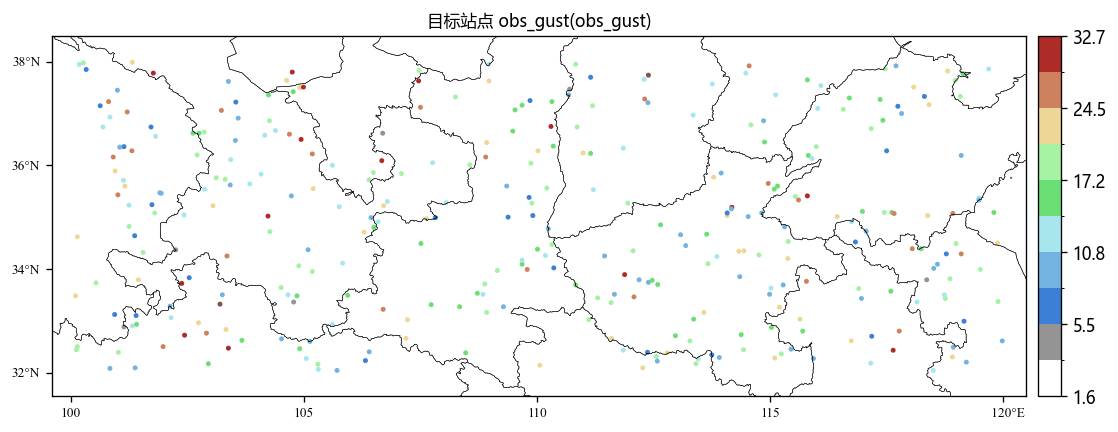

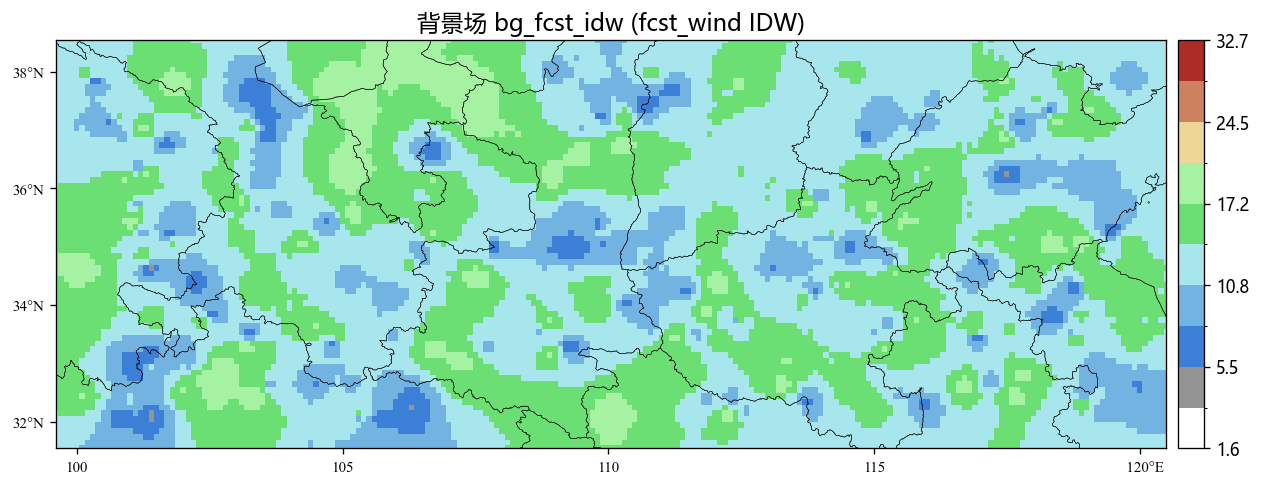

In [2]:
# 读站：CSV 无时间列时按文件名补 time；本例取 dtime=24
sta = meb.read_stadata_from_csv(str(DATA_DIR / "20260602000000.csv")).copy()
sta["time"] = pd.to_datetime("2026-06-02")
sta = meb.sele_by_para(sta, dtime=24)
obs = sta[["level", "time", "dtime", "id", "lon", "lat", "obs_gust"]].copy()
fcst = sta[["level", "time", "dtime", "id", "lon", "lat", "fcst_wind"]].copy()

lon0, lon1 = float(obs.lon.min()) - 0.5, float(obs.lon.max()) + 0.5
lat0, lat1 = float(obs.lat.min()) - 0.5, float(obs.lat.max()) + 0.5
tgt_grid = meb.basicdata.grid([lon0, lon1, 0.1], [lat0, lat1, 0.1])
MAP_EXTEND = [lon0, lon1, lat0, lat1]

# CLI 输入：目标空场 + 清洗后的单要素站点表（普通 CSV，无 meb attrs 头）
meb.write_griddata_to_nc(meb.grid_data(tgt_grid), str(DATA_DIR / "target_grid.nc"), creat_dir=True)
obs.to_csv(DATA_DIR / "obs_gust_d24.csv", index=False)

# 背景场：优先读 ShowDoc 同套 bg_fcst_idw.nc；缺失则用 fcst_wind IDW 生成
BG_PATH = DATA_DIR / "showdoc_demo" / "bg_fcst_idw.nc"
BG_PATH.parent.mkdir(parents=True, exist_ok=True)
if BG_PATH.is_file():
    bg = meb.read_griddata_from_nc(str(BG_PATH))
    print("loaded background", BG_PATH)
else:
    bg = InterpSgIdw(effectR=150000, nearNum=8, decrease=2).process(fcst, tgt_grid)
    meb.write_griddata_to_nc(bg, str(BG_PATH), creat_dir=True)
    print("wrote background", BG_PATH)

print("obs stations:", len(obs))
print("target grid:", tgt_grid.nlon, "x", tgt_grid.nlat)

# wind_speed 色表按数据范围裁剪（对比图可再算）
cmap_all, clevs_all = get_cmap_and_clevs_by_element_name("wind_speed")
z = np.asarray(obs["obs_gust"], dtype=float)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP, CLEVS = def_cmap_clevs(cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True)
CLEVS = np.asarray(CLEVS, dtype=float)
if len(CLEVS) > 12:
    CLEVS = CLEVS[:: int(np.ceil((len(CLEVS) - 1) / 11))]
    CMAP, CLEVS = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS, vmin=CLEVS[0], vmax=CLEVS[-1], cut_colorbar=True
    )
    CLEVS = np.asarray(CLEVS, dtype=float)
print("clevs =", CLEVS)

# 单图：height/width 控制图幅；站点用 point_size 加大散点
meb.scatter_sta(
    obs,
    title="目标站点 obs_gust",
    cmap=CMAP,
    clevs=CLEVS,
    map_extend=MAP_EXTEND,
    point_size=36,
    height=6.5,
    width=12,
    dpi=120,
    show=True,
)
meb.pcolormesh_2d_grid(
    bg,
    title="背景场 bg_fcst_idw (fcst_wind IDW)",
    cmap=CMAP,
    clevs=CLEVS,
    height=6.5,
    width=12,
    dpi=120,
    show=True,
)


## 4. 插件调用示例

### 4.1 InterpSgIdw


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[15.132091 , 14.435649 , 14.339102 , ..., 12.1301985,
            12.158875 , 12.193619 ],
           [15.381119 , 14.720163 , 14.633669 , ..., 12.032022 ,
            12.067951 , 12.1109   ],
           [15.670201 , 15.616135 , 14.995353 , ..., 11.919778 ,
            11.964888 , 12.018396 ],
           ...,
           [14.633559 , 14.67467  , 14.732019 , ..., 15.622587 ,
            15.742043 , 15.859599 ],
           [14.698105 , 15.361353 , 15.378199 , ..., 15.861113 ,
            15.93826  , 16.020248 ],
           [15.498287 , 15.507956 , 15.531102 , ..., 16.07618  ,
            16.121899 , 16.175762 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

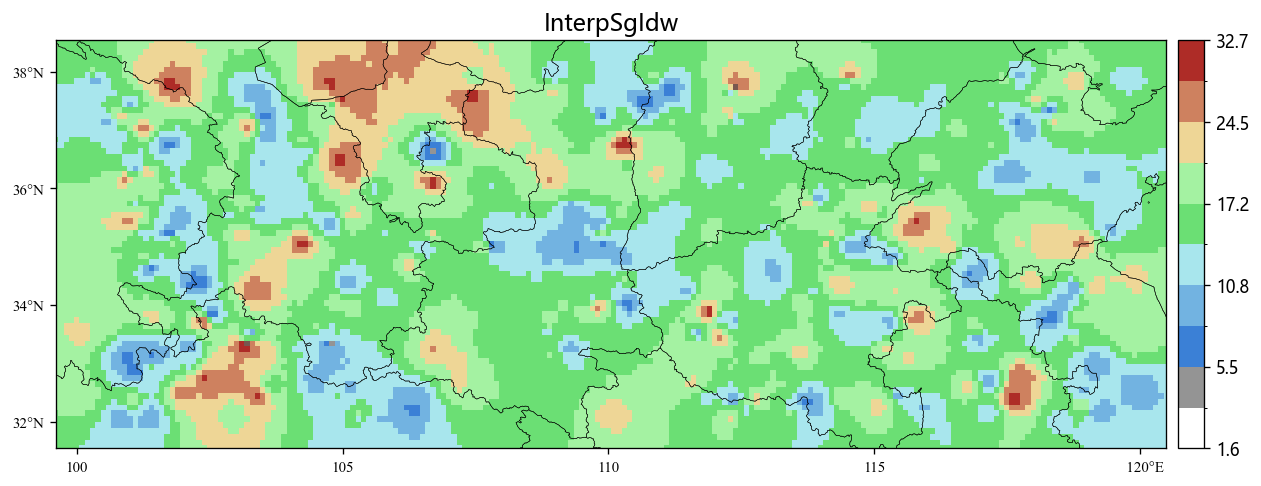

In [3]:
grd_idw = InterpSgIdw(effectR=150000, nearNum=8, decrease=2).process(obs, tgt_grid)
print(grd_idw)
meb.pcolormesh_2d_grid(
    grd_idw, title="InterpSgIdw", cmap=CMAP, clevs=CLEVS, height=6.5, width=12, dpi=120, show=True
)


### 4.2 InterpSgIdw（`gaussian=True`）

`effectR` 作高斯半径；权重为 `1/d^decrease * exp(-(d/effectR)^2)`。


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[15.132041 , 14.435607 , 14.339063 , ..., 12.130142 ,
            12.158815 , 12.193553 ],
           [15.381075 , 14.720126 , 14.633635 , ..., 12.031973 ,
            12.067897 , 12.11084  ],
           [15.670162 , 15.616099 , 14.995324 , ..., 11.919732 ,
            11.964838 , 12.018343 ],
           ...,
           [14.633534 , 14.674649 , 14.732001 , ..., 15.6225395,
            15.741988 , 15.859537 ],
           [14.698076 , 15.361323 , 15.378173 , ..., 15.861057 ,
            15.938199 , 16.02018  ],
           [15.498247 , 15.50792  , 15.531071 , ..., 16.076118 ,
            16.12183  , 16.175688 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

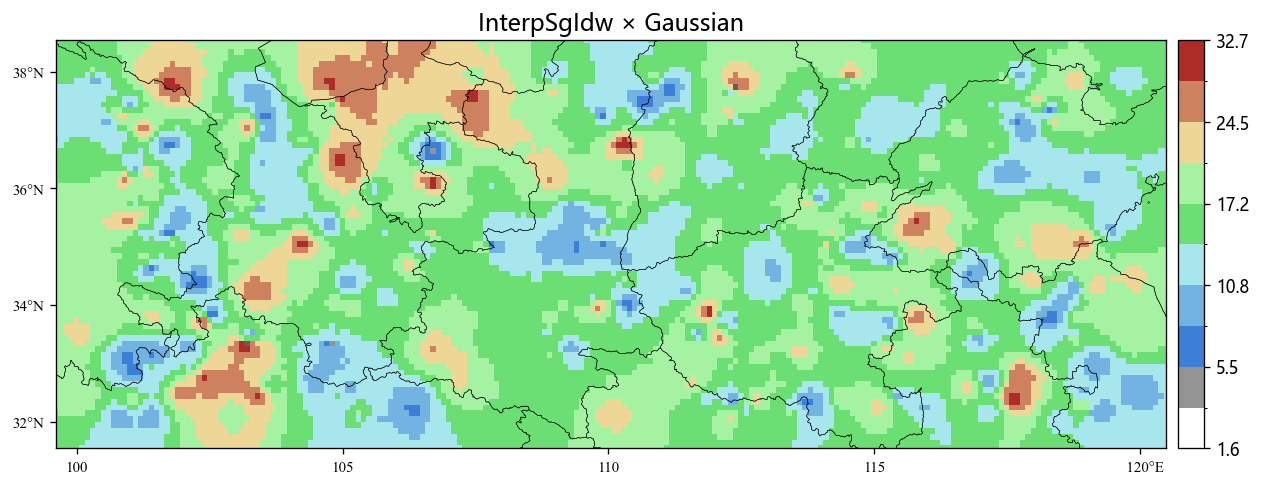

In [4]:
grd_idw_g = InterpSgIdw(
    effectR=80000, nearNum=8, decrease=2, gaussian=True
).process(obs, tgt_grid)
print(grd_idw_g)
meb.pcolormesh_2d_grid(
    grd_idw_g, title="InterpSgIdw × Gaussian", cmap=CMAP, clevs=CLEVS,
    height=6.5, width=12, dpi=120, show=True,
)


### 4.3 InterpSgGaussian


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[20.51996  , 20.519964 , 20.519966 , ...,  8.53998  ,
             8.539979 ,  8.539978 ],
           [20.519968 , 20.51997  , 20.519972 , ...,  8.539983 ,
             8.539983 ,  8.539981 ],
           [20.519974 , 20.519976 , 20.519978 , ...,  8.539987 ,
             8.539986 ,  8.539985 ],
           ...,
           [13.259991 , 13.259993 , 13.2599945, ..., 10.919991 ,
            10.919989 , 10.919987 ],
           [13.259989 , 13.259991 , 13.259992 , ..., 10.919988 ,
            10.919987 , 10.919985 ],
           [13.259986 , 13.259988 , 13.259989 , ..., 10.919986 ,
            10.919984 , 10.919982 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

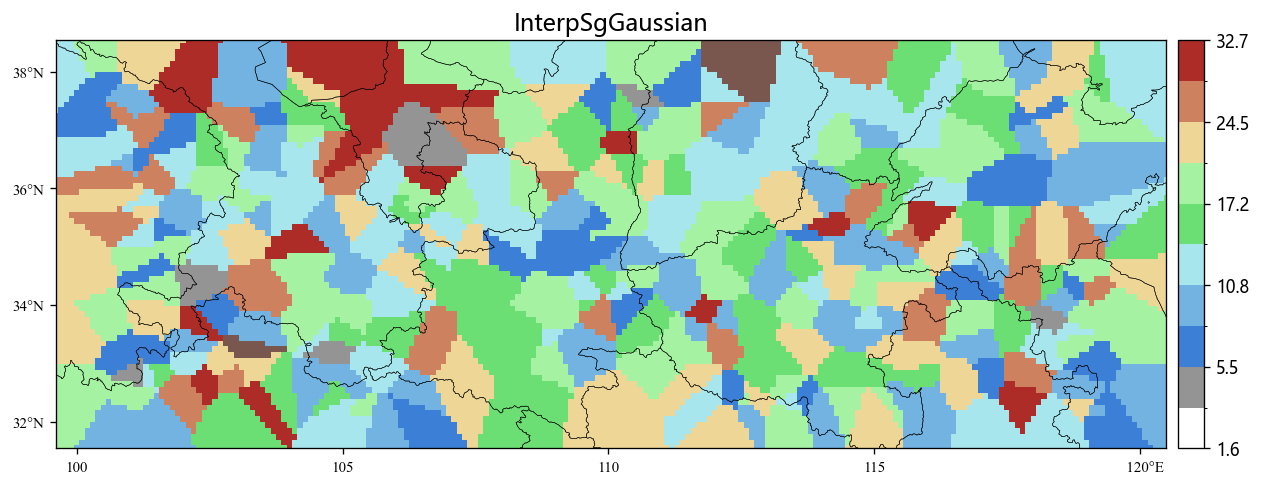

In [5]:
grd_gauss = InterpSgGaussian(halfR=80000).process(obs, tgt_grid)
print(grd_gauss)
meb.pcolormesh_2d_grid(
    grd_gauss, title="InterpSgGaussian", cmap=CMAP, clevs=CLEVS,
    height=6.5, width=12, dpi=120, show=True,
)


### 4.4 InterpSgKriging


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[17.005768 , 16.501583 , 15.962619 , ..., 10.510852 ,
            10.85803  , 11.24303  ],
           [17.341656 , 16.835306 , 16.286818 , ..., 10.215047 ,
            10.58847  , 11.32726  ],
           [16.90556  , 17.241518 , 16.694263 , ...,  9.956402 ,
            10.626961 , 11.079279 ],
           ...,
           [16.014214 , 16.471975 , 16.467232 , ..., 10.5098295,
            10.361869 , 10.230801 ],
           [16.761734 , 16.43899  , 17.064661 , ..., 11.055417 ,
            10.390672 , 10.246423 ],
           [16.35297  , 16.908276 , 17.50143  , ..., 11.12132  ,
            10.99923  , 10.256142 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) f

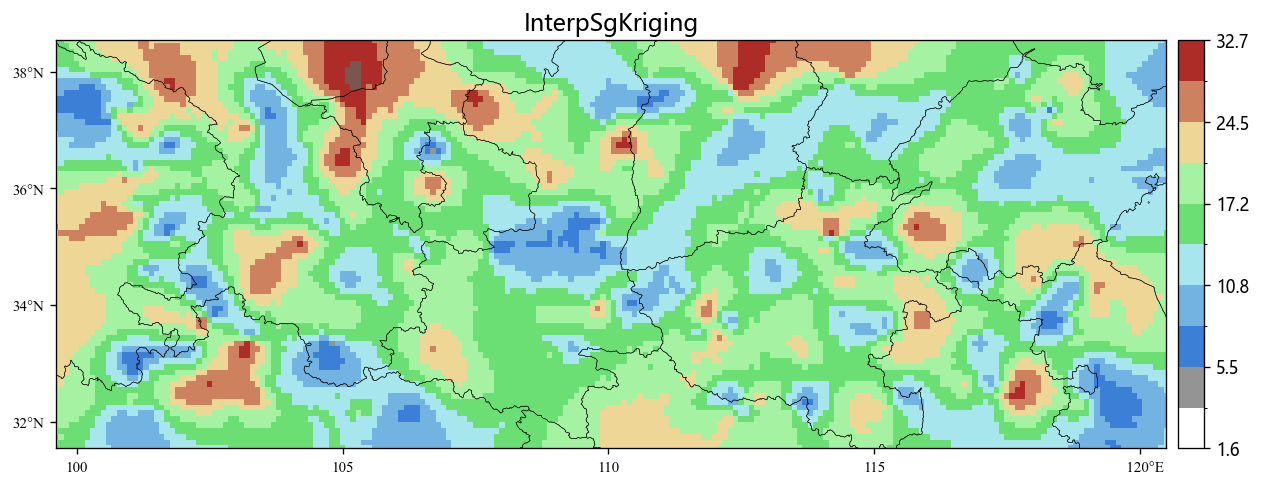

In [6]:
grd_krig = InterpSgKriging(model="spherical", nearNum=12).process(obs, tgt_grid)
print(grd_krig)
meb.pcolormesh_2d_grid(
    grd_krig, title="InterpSgKriging", cmap=CMAP, clevs=CLEVS,
    height=6.5, width=12, dpi=120, show=True,
)


### 4.5 InterpSgCressman


<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[18.450962, 18.450964, 18.450968, ..., 15.327034,
            15.327035, 15.327037],
           [18.714396, 18.450966, 18.450968, ..., 15.327037,
            15.327038, 15.327039],
           [18.714396, 18.7144  , 18.450968, ..., 15.327039,
            15.32704 , 15.327042],
           ...,
           [15.686545, 15.686543, 15.083184, ..., 15.791321,
            15.791324, 15.791326],
           [15.686544, 15.686542, 15.083184, ..., 15.791317,
            15.791319, 15.791321],
           [15.686543, 15.083186, 15.083183, ..., 15.791312,
            15.791315, 15.791317]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_gust'
  * level    (level) float32 4B 0.0
  * time     (time) datetime64[ns] 8B 2026-06-02
  * dtime    (dtime) int32 4B 24
  * lat      (lat) float64 568B 31.54 31.64 31.74 31.84 

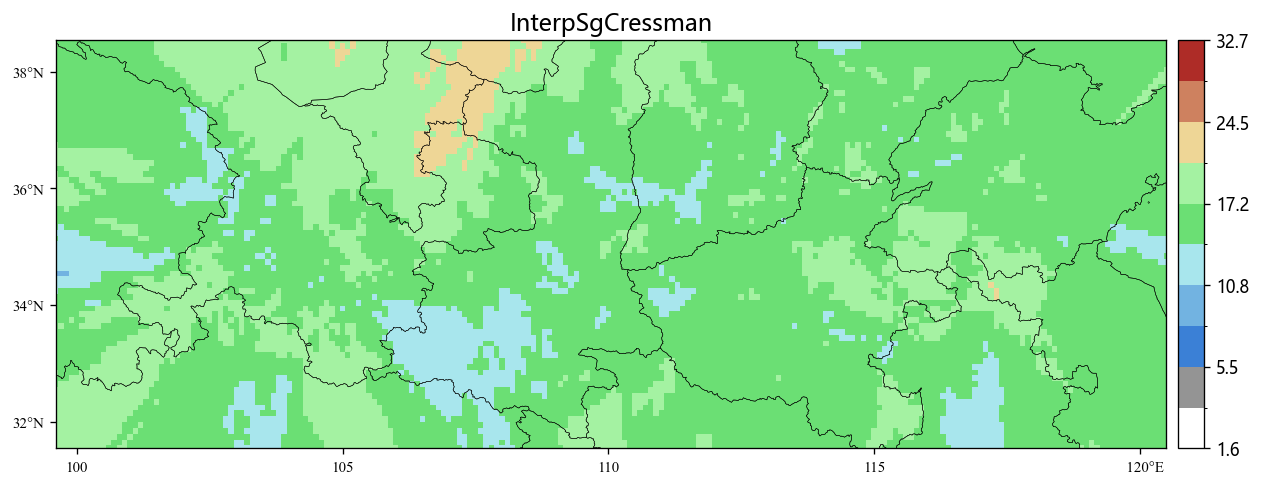

compare clevs = [ 1.6  3.4  5.5  8.  10.8 13.9 17.2 20.8 24.5 28.5 32.7]


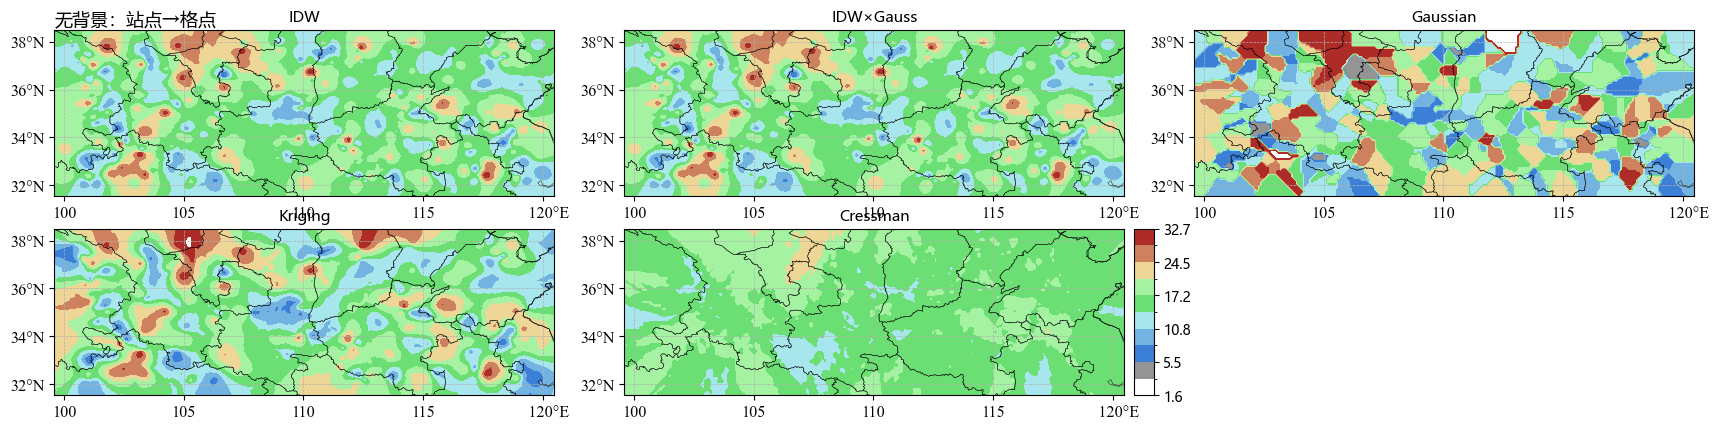

In [7]:
grd_cress = InterpSgCressman(
    r_list=[200000, 100000, 50000], nearNum=40
).process(obs, tgt_grid)
print(grd_cress)
meb.pcolormesh_2d_grid(
    grd_cress, title="InterpSgCressman", cmap=CMAP, clevs=CLEVS,
    height=6.5, width=12, dpi=120, show=True,
)

# 五方法对比：按无背景结果重算色阶，creat_axs 统一底图
nobg = {
    "IDW": grd_idw,
    "IDW×Gauss": grd_idw_g,
    "Gaussian": grd_gauss,
    "Kriging": grd_krig,
    "Cressman": grd_cress,
}
z = np.concatenate(
    [np.asarray(obs["obs_gust"], dtype=float).ravel()]
    + [np.asarray(g.values, dtype=float).ravel() for g in nobg.values()]
)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP, CLEVS = def_cmap_clevs(cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True)
CLEVS = np.asarray(CLEVS, dtype=float)
if len(CLEVS) > 12:
    CLEVS = CLEVS[:: int(np.ceil((len(CLEVS) - 1) / 11))]
    CMAP, CLEVS = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS, vmin=CLEVS[0], vmax=CLEVS[-1], cut_colorbar=True
    )
    CLEVS = np.asarray(CLEVS, dtype=float)
print("compare clevs =", CLEVS)

titles = list(nobg.keys())
n, ncol = len(titles), min(3, len(titles))
axs = meb.creat_axs(
    n, MAP_EXTEND, ncol=ncol, height=7, width=7 * ncol, dpi=100,
    title_list=titles, wspace=0.7, sup_title="无背景：站点→格点", sup_fontsize=13,
)
for i, name in enumerate(titles):
    meb.add_contourf(
        axs[i], nobg[name], cmap=CMAP, clevs=CLEVS,
        add_colorbar=(i == n - 1), title=name, title_fontsize=11,
    )
plt.show()


## 5. 带背景场的偏差订正示例

四个插件都支持 `background`。本例直接使用 §3 已准备的 `resource/showdoc_demo/bg_fcst_idw.nc`（`fcst_wind` IDW，与 ShowDoc 同套），再对 `obs_gust` 调用：

- IDW / IDW×高斯 / Gaussian / Kriging：偏差订正（插 `obs−bg` 再叠回）
- Cressman：以背景为初估场做逐步订正


background       min=5.20 max=19.94
IDW+bg           min=3.06 max=33.53
IDW×Gauss+bg     min=3.06 max=33.53
Gaussian+bg      min=2.91 max=35.62
Kriging+bg       min=3.21 max=33.73
Cressman+bg      min=7.47 max=25.16


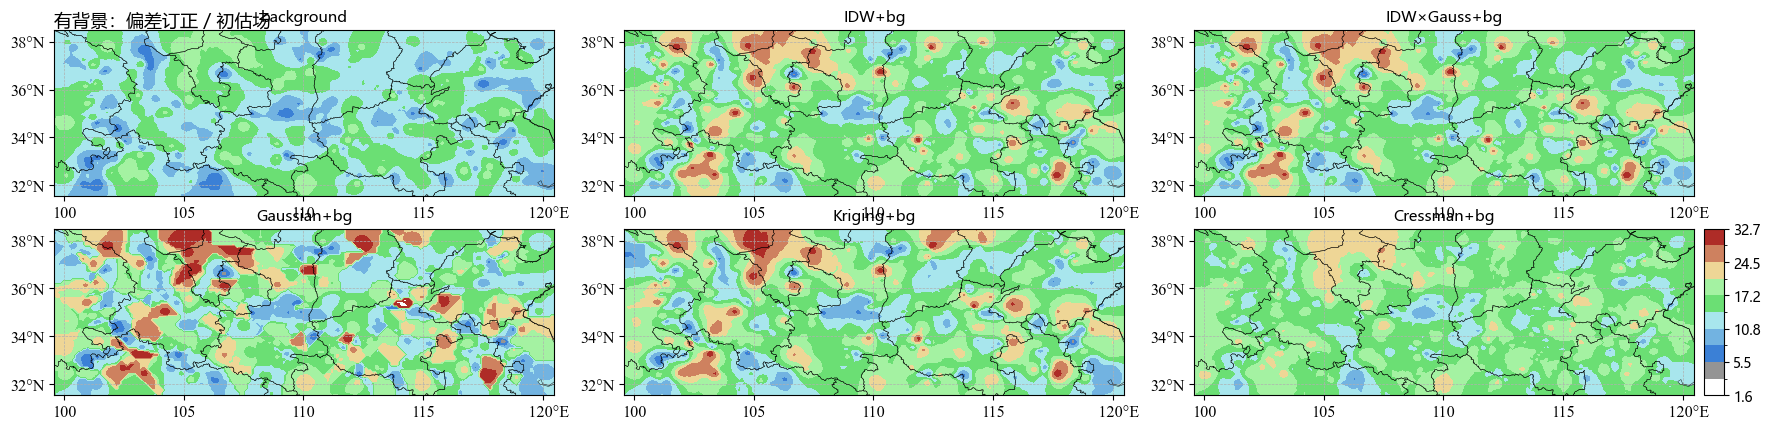

In [8]:
# bg 已在 §3 读入 / 写出为 showdoc_demo/bg_fcst_idw.nc
with_bg = {
    "background": bg,
    "IDW+bg": InterpSgIdw(
        effectR=150000, nearNum=8, decrease=2, outer_value=0.0
    ).process(obs, tgt_grid, background=bg),
    "IDW×Gauss+bg": InterpSgIdw(
        effectR=80000, nearNum=8, decrease=2, gaussian=True, outer_value=0.0
    ).process(obs, tgt_grid, background=bg),
    "Gaussian+bg": InterpSgGaussian(halfR=80000, outer_value=0.0).process(
        obs, tgt_grid, background=bg
    ),
    "Kriging+bg": InterpSgKriging(
        model="spherical", nearNum=12, outer_value=0.0
    ).process(obs, tgt_grid, background=bg),
    "Cressman+bg": InterpSgCressman(
        r_list=[200000, 100000, 50000], nearNum=40, outer_value=0.0
    ).process(obs, tgt_grid, background=bg),
}

for k, da in with_bg.items():
    z = np.asarray(da.values, dtype=float)
    print(f"{k:16s} min={np.nanmin(z):.2f} max={np.nanmax(z):.2f}")

z = np.concatenate(
    [np.asarray(obs["obs_gust"], dtype=float).ravel()]
    + [np.asarray(g.values, dtype=float).ravel() for g in with_bg.values()]
)
z = z[np.isfinite(z)]
vmin, vmax = float(np.nanpercentile(z, 1)), float(np.nanpercentile(z, 99))
CMAP_BG, CLEVS_BG = def_cmap_clevs(
    cmap=cmap_all, clevs=clevs_all, vmin=vmin, vmax=vmax, cut_colorbar=True
)
CLEVS_BG = np.asarray(CLEVS_BG, dtype=float)
if len(CLEVS_BG) > 12:
    CLEVS_BG = CLEVS_BG[:: int(np.ceil((len(CLEVS_BG) - 1) / 11))]
    CMAP_BG, CLEVS_BG = def_cmap_clevs(
        cmap=cmap_all, clevs=CLEVS_BG, vmin=CLEVS_BG[0], vmax=CLEVS_BG[-1], cut_colorbar=True
    )
    CLEVS_BG = np.asarray(CLEVS_BG, dtype=float)

titles = list(with_bg.keys())
n, ncol = len(titles), min(3, len(titles))
axs = meb.creat_axs(
    n, MAP_EXTEND, ncol=ncol, height=7, width=7 * ncol, dpi=100,
    title_list=titles, wspace=0.7, sup_title="有背景：偏差订正 / 初估场", sup_fontsize=13,
)
for i, name in enumerate(titles):
    meb.add_contourf(
        axs[i], with_bg[name], cmap=CMAP_BG, clevs=CLEVS_BG,
        add_colorbar=(i == n - 1), title=name, title_fontsize=11,
    )
plt.show()


## 6. CLI 使用示例

在包目录等价于：

```bash
python -m cli --module idw --sta resource/obs_gust_d24.csv --grid resource/target_grid.nc --output resource/cli_idw_out.nc --effect-r 150000 --near-num 8 --decrease 2
```

下面用 `InterpolationStationGridCli.call` 调度，输出写到 `resource/`。


level,time,dtime,id,lon,lat,obs_gust

站点数据缺属性说明，已自动赋值默认值，使用需谨慎
写出 → D:\workspace\test\00temp\interpolation_station_grid\resource\cli_idw_out.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 1, lat: 71,
                           lon: 210)> Size: 60kB
array([[[[[[15.132091 , 14.435649 , 14.339102 , ..., 12.1301985,
            12.158875 , 12.193619 ],
           [15.381119 , 14.720163 , 14.633669 , ..., 12.032022 ,
            12.067951 , 12.1109   ],
           [15.670201 , 15.616135 , 14.995353 , ..., 11.919778 ,
            11.964888 , 12.018396 ],
           ...,
           [14.633559 , 14.67467  , 14.732019 , ..., 15.622587 ,
            15.742043 , 15.859599 ],
           [14.698105 , 15.361353 , 15.378199 , ..., 15.861113 ,
            15.93826  , 16.020248 ],
           [15.498287 , 15.507956 , 15.531102 , ..., 16.07618  ,
            16.121899 , 16.175762 ]]]]]],
      shape=(1, 1, 1, 1, 71, 210), dtype=float32)
Coordinates:
  * member   (member) <U8 32B 'obs_

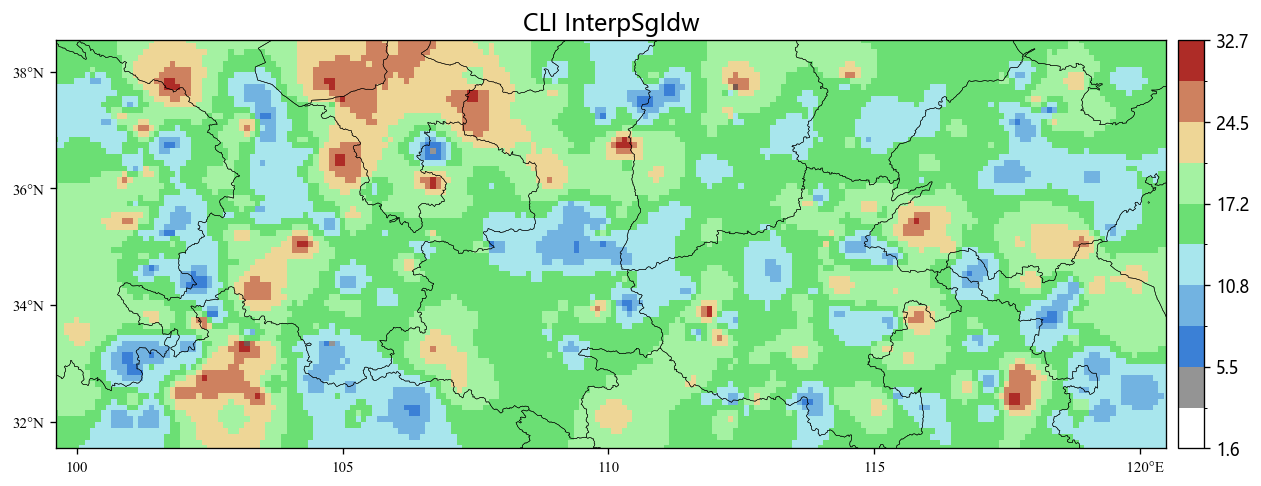

In [9]:
from cli.interpolation_station_grid_cli import InterpolationStationGridCli

out_nc = str(DATA_DIR / "cli_idw_out.nc")
rc = InterpolationStationGridCli.call(
    module="idw",
    sta=str(DATA_DIR / "obs_gust_d24.csv"),
    grid=str(DATA_DIR / "target_grid.nc"),
    output=out_nc,
    effect_r=150000,
    near_num=8,
    decrease=2,
    sta_type="csv",
    grid_type="nc",
    output_type="nc",
)
print("return code =", rc)
print("output =", out_nc)

grd_cli = meb.read_griddata_from_nc(out_nc)
print(grd_cli)
meb.pcolormesh_2d_grid(
    grd_cli, title="CLI InterpSgIdw", cmap=CMAP, clevs=CLEVS,
    height=6.5, width=12, dpi=120, show=True,
)


## 7. 小结

- 插件接口统一：`process(sta, grid, background=None)`。
- 样例：`resource/20260602000000.csv`（本例整理为 `obs_gust_d24.csv`）+ `resource/target_grid.nc`；背景场见 `resource/showdoc_demo/bg_fcst_idw.nc`。
- 读站 CSV 无属性头时，`meb.read_stadata_from_csv` 会打印「站点数据缺属性说明…」并赋默认 attrs。
- 绘图直接调 `meb.scatter_sta` / `pcolormesh_2d_grid`（`height`/`width`/`point_size`）；对比用 `creat_axs`；背景场不叠实况站。
- CLI：`python -m cli --module idw|gaussian|kriging|cressman`，输出示例见 `resource/cli_idw_out.nc`；站点 `csv|m3`，格点 `nc|m4`。
- 选型：平滑分析常用 IDW / Gaussian；空间相关结构更复杂时试 Kriging；有较好背景场时用偏差订正或 Cressman 逐步订正。
